# Notebook 03
* Author: Melissa Ormeño; Alexis Salas
* Laboratory: Cancer Molecular Dynamics
* Date: May 2024

Aims:
* Define las mutaciones del ICGC y las clasifica por su frecuencia de alelo mutante

In [5]:
# Dependences
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
import pwlf
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold
from scipy.stats import f_oneway, kruskal, shapiro

# Step 1: filtrar data frame 

In [7]:
# Datos con la lista de genes quinasa a trabajar 
#interpro_code = 'IPR000333'
family_name = 'STKR'
df = pd.read_csv('../data/Cancer/df_icgc_{0}.csv'.format(family_name))
df.columns

Index(['Gen_names', 'Uniprot Name', 'Aliases', 'Uniprot ID', 'ENS ID', 'Group',
       'icgc_mutation_id', 'icgc_donor_id', 'project_code', 'icgc_specimen_id',
       'icgc_sample_id', 'matched_icgc_sample_id', 'submitted_sample_id',
       'submitted_matched_sample_id', 'chromosome', 'chromosome_start',
       'chromosome_end', 'chromosome_strand', 'assembly_version',
       'mutation_type', 'reference_genome_allele', 'mutated_from_allele',
       'mutated_to_allele', 'total_read_count', 'mutant_allele_read_count',
       'verification_status', 'verification_platform',
       'biological_validation_status', 'biological_validation_platform',
       'consequence_type', 'aa_mutation', 'cds_mutation', 'gene_affected',
       'transcript_affected', 'gene_build_version', 'platform',
       'experimental_protocol', 'sequencing_strategy',
       'base_calling_algorithm', 'alignment_algorithm',
       'variation_calling_algorithm', 'other_analysis_algorithm',
       'seq_coverage', 'tipo_cance

In [8]:
#Lee el contenido de algunas columnas del data frame df, que contiene el archivo "simple_somatic_mutation.open.tsv.gz" del ICGC
print(f"Assembly_version: {df['assembly_version'].unique()}")
print(f"Gene_build_version: {df['gene_build_version'].unique()}")
#print(f"base_calling_algorithm: {df['base_calling_algorithm'].unique()}")
#print(f"alignment_algorithm: {df['alignment_algorithm'].unique()}")
#print(f"experimental_protocol: {df['experimental_protocol'].unique()}")
print(f"biological_validation_status: {df['biological_validation_status'].unique()}")
print(f"biological_validation_platform: {df['biological_validation_platform'].unique()}")
print(f"verification_status: {df['verification_status'].unique()}")
print(f"mutation_type: {df['mutation_type'].unique()}")
print(f"consequence_type: {df['consequence_type'].unique()}")

Assembly_version: ['GRCh37']
Gene_build_version: [75.]
biological_validation_status: ['not tested' nan 'tested and valid']
biological_validation_platform: [nan 'PCR' 'capillary sequencing' '454 sequencing']
verification_status: ['not tested' 'tested and verified' 'tested and verified to be false']
mutation_type: ['single base substitution'
 'multiple base substitution (>=2bp and <=200bp)' 'deletion of <=200bp'
 'insertion of <=200bp']
consequence_type: ['synonymous_variant' 'missense_variant' 'stop_gained'
 'frameshift_variant' 'disruptive_inframe_insertion' 'inframe_deletion'
 'start_lost' 'stop_lost' 'stop_retained_variant']


In [9]:
# Crea una nueva columna combinando 'tipo_cancer' y 'project_code'
df['cancer_name'] = df['tipo_cancer'] + '_' + df['project_code']
# Mostrar el DataFrame para verificar
print(df['cancer_name'].unique())
df.head(2)



['Piel_SKCM-US' 'Piel_SKCA-BR' 'Piel_MELA-AU' 'Higado_LIRI-JP'
 'Higado_LINC-JP' 'Higado_LIHC-US' 'Higado_LIAD-FR' 'Higado_LICA-FR'
 'Sangre_MALY-DE' 'Sangre_LAML-US' 'Sangre_CLLE-ES' 'Sangre_LAML-KR'
 'Cerebro_GBM-US' 'Cerebro_LGG-US' 'Cerebro_PBCA-DE' 'Cerebro_PEME-CA'
 'Seno _BRCA-US' 'Seno _BRCA-EU' 'Seno _BRCA-UK' 'Seno _BRCA-FR'
 'Ovario_OV-US' 'Ovario_OV-AU' 'Pancreas_PACA-CA' 'Pancreas_PAEN-AU'
 'Pancreas_PAAD-US' 'Pancreas_PACA-AU' 'Pancreas_PAEN-IT'
 'Prostata_PRAD-US' 'Prostata_PRAD-CA' 'Prostata_PRAD-CN'
 'Prostata_PRAD-FR' 'Prostata_PRAD-UK' 'Prostata_EOPC-DE' 'Utero_UCEC-US'
 'Utero_UTCA-FR' 'Estomago_GACA-CN' 'Estomago_STAD-US' 'Pulmon_LUAD-US'
 'Pulmon_LUSC-US' 'Pulmon_LUSC-KR' 'Riñon_KIRC-US' 'Riñon_RECA-EU'
 'Riñon_KIRP-US' 'Riñon_WT-US' 'Riñon_KICH-US' 'Cabeza_HNSC-US'
 'Cabeza_THCA-US' 'Cabeza_THCA-SA' 'Cabeza_ORCA-IN' 'Gladd_BTCA-JP'
 'Gladd_BTCA-SG' 'Colon_READ-US' 'Colon_COAD-US' 'Cervix_CESC-US'
 'Hueso_BOCA-UK' 'Vejiga_BLCA-US']


,Gen_names,Uniprot Name,Aliases,Uniprot ID,ENS ID,Group,icgc_mutation_id,icgc_donor_id,project_code,icgc_specimen_id,...,platform,experimental_protocol,sequencing_strategy,base_calling_algorithm,alignment_algorithm,variation_calling_algorithm,other_analysis_algorithm,seq_coverage,tipo_cancer,cancer_name
0,BMPR1B,BMR1B_HUMAN,"ALK-6, ALK6, AMD3, AMDD, BDA1D, BDA2, CDw293",O00238,ENSG00000138696,TKL,MU4433033,DO37607,SKCM-US,SP82796,...,Illumina GA sequencing,NaN,WXS,NaN,NaN,TCGA-MC3 https://gdc.cancer.gov/about-data/pub...,NaN,NaN,Piel,Piel_SKCM-US
1,BMPR1B,BMR1B_HUMAN,"ALK-6, ALK6, AMD3, AMDD, BDA1D, BDA2, CDw293",O00238,ENSG00000138696,TKL,MU4433033,DO37607,SKCM-US,SP82796,...,Illumina GA sequencing,NaN,WXS,NaN,NaN,TCGA-MC3 https://gdc.cancer.gov/about-data/pub...,NaN,NaN,Piel,Piel_SKCM-US


In [10]:
#Se obtiene una lista del tipo de cancer y el proyecto paricular para cada tipo de cancer

# Obtener la lista de tipos de cáncer
list_tipo_cancer = df['tipo_cancer'].unique()

# Crear un diccionario para almacenar los resultados
resultados = {}

# Iterar sobre cada tipo de cáncer y obtener los códigos únicos de proyectos
for tipo in list_tipo_cancer:
    proyectos_unicos = df[df['tipo_cancer'] == tipo]['project_code'].unique()
    resultados[tipo] = proyectos_unicos

# Mostrar los resultados
for tipo, proyectos in resultados.items():
    print(f"{tipo}: {proyectos}")


Piel: ['SKCM-US' 'SKCA-BR' 'MELA-AU']
Higado: ['LIRI-JP' 'LINC-JP' 'LIHC-US' 'LIAD-FR' 'LICA-FR']
Sangre: ['MALY-DE' 'LAML-US' 'CLLE-ES' 'LAML-KR']
Cerebro: ['GBM-US' 'LGG-US' 'PBCA-DE' 'PEME-CA']
Seno : ['BRCA-US' 'BRCA-EU' 'BRCA-UK' 'BRCA-FR']
Ovario: ['OV-US' 'OV-AU']
Pancreas: ['PACA-CA' 'PAEN-AU' 'PAAD-US' 'PACA-AU' 'PAEN-IT']
Prostata: ['PRAD-US' 'PRAD-CA' 'PRAD-CN' 'PRAD-FR' 'PRAD-UK' 'EOPC-DE']
Utero: ['UCEC-US' 'UTCA-FR']
Estomago: ['GACA-CN' 'STAD-US']
Pulmon: ['LUAD-US' 'LUSC-US' 'LUSC-KR']
Riñon: ['KIRC-US' 'RECA-EU' 'KIRP-US' 'WT-US' 'KICH-US']
Cabeza: ['HNSC-US' 'THCA-US' 'THCA-SA' 'ORCA-IN']
Gladd: ['BTCA-JP' 'BTCA-SG']
Colon: ['READ-US' 'COAD-US']
Cervix: ['CESC-US']
Hueso: ['BOCA-UK']
Vejiga: ['BLCA-US']


In [11]:
#Selecciona las columnas que se utilizaran para el analisis
df_cancer= df[['Gen_names', 'icgc_donor_id', 'project_code','mutation_type', 'consequence_type','reference_genome_allele','icgc_specimen_id','icgc_mutation_id',
       'icgc_sample_id','reference_genome_allele', 'mutated_from_allele',
       'mutated_to_allele','mutation_type', 'total_read_count', 'mutant_allele_read_count',
       'verification_status', 'aa_mutation', 'cds_mutation','platform','sequencing_strategy', 'tipo_cancer']]
print(df_cancer.shape)
df_cancer.head()

(7678, 21)


,Gen_names,icgc_donor_id,project_code,mutation_type,consequence_type,reference_genome_allele,icgc_specimen_id,icgc_mutation_id,icgc_sample_id,reference_genome_allele,...,mutated_to_allele,mutation_type,total_read_count,mutant_allele_read_count,verification_status,aa_mutation,cds_mutation,platform,sequencing_strategy,tipo_cancer
0,BMPR1B,DO37607,SKCM-US,single base substitution,synonymous_variant,C,SP82796,MU4433033,SA438378,C,...,T,single base substitution,21.0,8.0,not tested,L192L,576C>T,Illumina GA sequencing,WXS,Piel
1,BMPR1B,DO37607,SKCM-US,single base substitution,synonymous_variant,C,SP82796,MU4433033,SA438378,C,...,T,single base substitution,21.0,8.0,not tested,L222L,666C>T,Illumina GA sequencing,WXS,Piel
2,BMPR1B,DO37607,SKCM-US,single base substitution,synonymous_variant,C,SP82796,MU4433033,SA438378,C,...,T,single base substitution,21.0,8.0,not tested,L192L,576C>T,Illumina GA sequencing,WXS,Piel
3,BMPR1B,DO37607,SKCM-US,single base substitution,synonymous_variant,C,SP82796,MU4433033,SA438378,C,...,T,single base substitution,21.0,8.0,not tested,L192L,576C>T,Illumina GA sequencing,WXS,Piel
4,BMPR1B,DO37607,SKCM-US,single base substitution,synonymous_variant,C,SP82796,MU4433033,SA438378,C,...,T,single base substitution,21.0,8.0,not tested,L192L,576C>T,Illumina GA sequencing,WXS,Piel


In [12]:
df_cancer['verification_status'].unique()

array(['not tested', 'tested and verified',
       'tested and verified to be false'], dtype=object)

In [13]:
#Crea un data frame donde solo esten los datos que han sido verificados y que no esten testeados
#Seleccionar filas donde la columna 'verification_status' sea 'tested and verified' o 'tested and verified to be false'
df_verificado = df_cancer.loc[(df_cancer['verification_status'] == 'tested and verified') | (df_cancer['verification_status'] == 'not tested')]
print(df_verificado['verification_status'].unique())
print(df_verificado.shape)

['not tested' 'tested and verified']
(7672, 21)


In [14]:
df_verificado['consequence_type'].unique()

array(['synonymous_variant', 'missense_variant', 'stop_gained',
       'frameshift_variant', 'disruptive_inframe_insertion',
       'inframe_deletion', 'start_lost', 'stop_lost',
       'stop_retained_variant'], dtype=object)

In [15]:
# elimina las mutaciones synonymous (silenciosas) y crea un data frame: df_drop
df_consequence=df_verificado[df_verificado['consequence_type'] != 'synonymous_variant'].reset_index(drop=True)
print(df_consequence.shape)

(6121, 21)


In [16]:
# Agrupa el df por las columnas asociadas a la mutacion, como: gen, cromosoma, mutationID, tipo de consecuencia, tipo de cancer, etc
# Con esta columnas agrupadas se suma el total_read_count, y mutant_allele_read_count y se obtiene una columna de frecuencia de alelo mutante
df_drop=df_consequence.groupby(['Gen_names','aa_mutation', 'cds_mutation','mutated_from_allele','mutated_to_allele','consequence_type','project_code','tipo_cancer'], 
                            dropna=True).sum(numeric_only=True).reset_index()
df_drop['mutant_allele_frequency'] = df_drop['mutant_allele_read_count'] / df_drop['total_read_count']
print(df_drop.shape)
df_drop.sort_values(by='mutant_allele_frequency', ascending=True).head(10)

(3004, 11)


,Gen_names,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency
1776,BMPR1A,K372I,1115A>T,A,T,missense_variant,OV-US,Ovario,344.0,9.0,0.026163
2647,TGFBR1,S420F,1259C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933
2646,TGFBR1,S416F,1247C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933
2641,TGFBR1,S347F,1040C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933
2639,TGFBR1,S339F,1016C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933
2126,BMPR2,R147Q,440G>A,G,A,missense_variant,STAD-US,Estomago,492.0,14.0,0.028455
1641,AMHR2,P130S,388C>T,C,T,missense_variant,PACA-CA,Pancreas,396.0,12.0,0.030303
1648,AMHR2,P433S,1297C>T,C,T,missense_variant,PACA-CA,Pancreas,396.0,12.0,0.030303
1025,ACVR2A,P170A,508C>G,C,G,missense_variant,PAAD-US,Pancreas,1104.0,38.0,0.034420
1041,ACVR2A,P62A,184C>G,C,G,missense_variant,PAAD-US,Pancreas,552.0,19.0,0.034420


In [17]:
df_drop['aa_mutation'].nunique()

2624

In [18]:
df_drop.shape

(3004, 11)

# Step 2: Distribucion de la frecuencia de mutaciones

* Crea un grafico de  distribuciones de la frecuencia de las mutaciones del icgc en cancer. Ademas se obtienen caracteristicas descriptivas del data frame (media y desviacion estandar)
* Se define un umbral superior (media mas 2 desviaciones estandar) e inferior (media menos 2 desviaciones estandar)

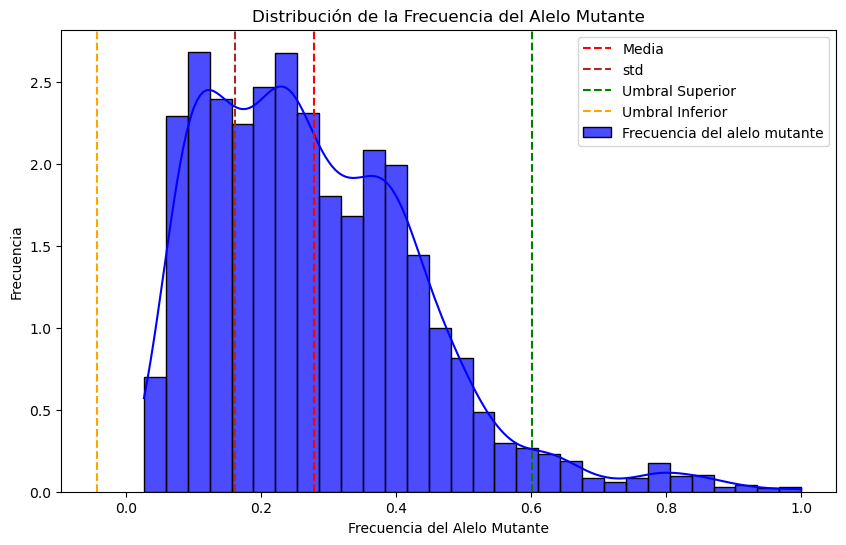

Media: 0.278714151219362
Desviacion estandar: 0.16132241413056878
Umbral superior: 0.6013589794804995
Umbral inferior: -0.04393067704177556


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular la media y la desviación estándar de la frecuencia del alelo mutante
mean_frequency = df_drop['mutant_allele_frequency'].mean()
std_dev_frequency = df_drop['mutant_allele_frequency'].std()

# Establecer umbrales como múltiplos de la desviación estándar de la media
threshold_upper = mean_frequency + 2 * std_dev_frequency  # Por ejemplo, una desviaciones estándar por encima de la media
threshold_lower = mean_frequency - 2 * std_dev_frequency  # Por ejemplo, una desviaciones estándar por debajo de la media

# Filtrar datos usando umbrales
filtered_df = df_drop[(df_drop['mutant_allele_frequency'] >= threshold_lower) & (df_drop['mutant_allele_frequency'] <= threshold_upper)]

# Crear el histograma de la frecuencia del alelo mutante
plt.figure(figsize=(10, 6))
sns.histplot(df_drop['mutant_allele_frequency'], bins=30, kde=True, color='blue', alpha=0.7, stat='density',label='Frecuencia del alelo mutante')
plt.axvline(mean_frequency, color='red', linestyle='--', label='Media')
plt.axvline(std_dev_frequency, color='brown', linestyle='--', label='std')
plt.axvline(threshold_upper, color='green', linestyle='--', label='Umbral Superior')
plt.axvline(threshold_lower, color='orange', linestyle='--', label='Umbral Inferior')
plt.title('Distribución de la Frecuencia del Alelo Mutante')
plt.xlabel('Frecuencia del Alelo Mutante')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()
print(f'Media: {mean_frequency}')
print(f'Desviacion estandar: {std_dev_frequency}')
print(f'Umbral superior: {threshold_upper}')
print(f'Umbral inferior: {threshold_lower}')

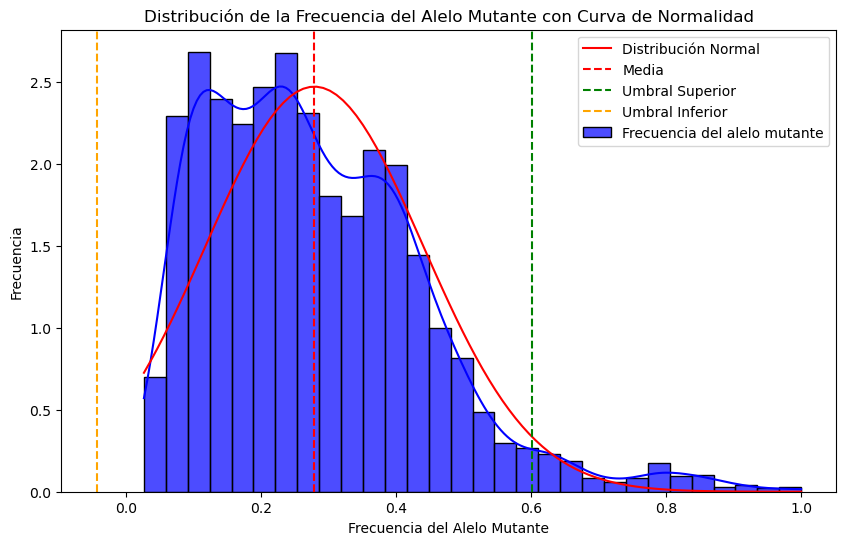

Media: 0.278714
Desviacion estandar: 0.161322
Umbral superior: 0.601359
Umbral inferior: -0.043931


In [20]:
#GRafico con curva de normalidad
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm

# Calcular la media y la desviación estándar de la frecuencia del alelo mutante
mean_frequency = df_drop['mutant_allele_frequency'].mean()
std_dev_frequency = df_drop['mutant_allele_frequency'].std()

# Establecer umbrales como múltiplos de la desviación estándar de la media
threshold_upper = mean_frequency + 2 * std_dev_frequency  # Por ejemplo, una desviación estándar por encima de la media
threshold_lower = mean_frequency - 2 * std_dev_frequency  # Por ejemplo, una desviación estándar por debajo de la media

# Filtrar datos usando umbrales
filtered_df = df_drop[(df_drop['mutant_allele_frequency'] >= threshold_lower) & (df_drop['mutant_allele_frequency'] <= threshold_upper)]

# Crear el histograma de la frecuencia del alelo mutante
plt.figure(figsize=(10, 6))
sns.histplot(df_drop['mutant_allele_frequency'], bins=30, kde=True, color='blue', alpha=0.7, stat='density', label='Frecuencia del alelo mutante')

# Calcular la distribución normal
x = np.linspace(df_drop['mutant_allele_frequency'].min(), df_drop['mutant_allele_frequency'].max(), 100)
y = norm.pdf(x, mean_frequency, std_dev_frequency)

# Graficar la curva de densidad de probabilidad de la distribución normal
plt.plot(x, y, 'r-', label='Distribución Normal')

# Añadir líneas para la media y los umbrales
plt.axvline(mean_frequency, color='red', linestyle='--', label='Media')
plt.axvline(threshold_upper, color='green', linestyle='--', label='Umbral Superior')
plt.axvline(threshold_lower, color='orange', linestyle='--', label='Umbral Inferior')

# Etiquetas y leyenda
plt.title('Distribución de la Frecuencia del Alelo Mutante con Curva de Normalidad')
plt.xlabel('Frecuencia del Alelo Mutante')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

print(f'Media: {mean_frequency:2f}')
print(f'Desviacion estandar: {std_dev_frequency:2f}')
print(f'Umbral superior: {threshold_upper:2f}')
print(f'Umbral inferior: {threshold_lower:2f}')

In [21]:
df_drop.shape

(3004, 11)

# Step 3: Regresion lineal segmentada y Analisis estadistico
* df_drop

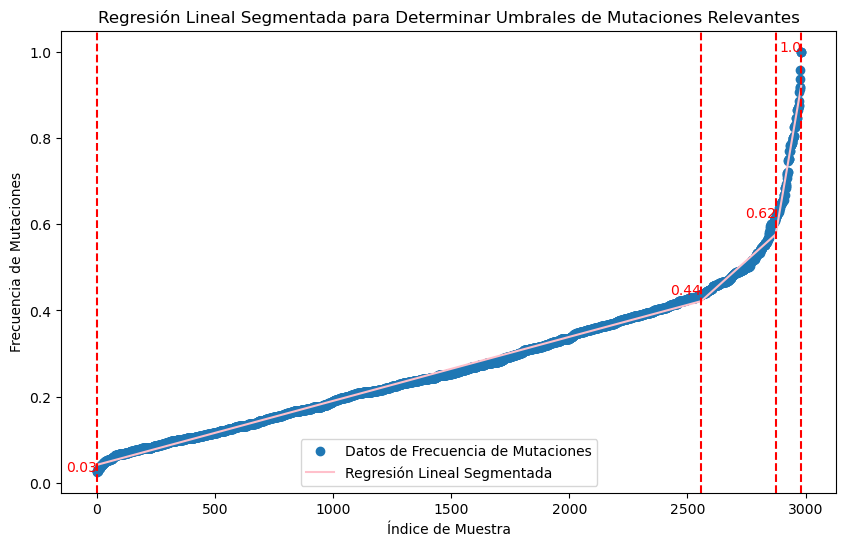

Error cuadratico medio (MSE): 6.973090952437656e-05
Coeficiente de determinacion (R²): 0.9973197113450483
Cross-Validated MSE: 0.0029469226529803398
ANOVA Result: F_onewayResult(statistic=1344.326424822226, pvalue=0.0)
Kruskal-Wallis Result: KruskalResult(statistic=1076.1322863668258, pvalue=5.4842723958150545e-233)
Shapiro-Wilk Test for Baja frecuencia: ShapiroResult(statistic=0.6904459685084313, pvalue=0.0048948910889035175)
Shapiro-Wilk Test for Media frecuencia: ShapiroResult(statistic=0.9592258599497554, pvalue=2.925653137752739e-26)
Shapiro-Wilk Test for Alta frecuencia: ShapiroResult(statistic=0.9147383070204144, pvalue=4.015005087711438e-12)
Shapiro-Wilk Test for Muy alta frecuencia: ShapiroResult(statistic=0.930081953432305, pvalue=3.300405602600985e-05)


In [22]:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import pwlf
    from sklearn.metrics import mean_squared_error, r2_score
    from sklearn.model_selection import KFold
    from scipy.stats import f_oneway, kruskal, shapiro



    # Asegurarse de que los datos están ordenados y eliminar NaNs e Infs
    df_drop = df_drop.sort_values(by='mutant_allele_frequency').reset_index(drop=True)
    df_drop = df_drop.replace([np.inf, -np.inf], np.nan).dropna(subset=['mutant_allele_frequency'])
    
    # Extraer la columna de frecuencias de mutaciones
    mutation_frequencies = df_drop['mutant_allele_frequency'].values
    
    # Definir el número de segmentos
    num_segments = 3  # Ajusta según sea necesario
    
    # Crear el modelo de regresión lineal segmentada
    piecewise_model = pwlf.PiecewiseLinFit(np.arange(len(mutation_frequencies)), mutation_frequencies)
    
    # Ajustar el modelo
    res = piecewise_model.fit(num_segments)
    
    # Predicciones
    y_pred = piecewise_model.predict(np.arange(len(mutation_frequencies)))
    
    # Obtener los puntos de cambio (breakpoints)
    breakpoints = piecewise_model.fit_breaks
    
    # Redondear los umbrales encontrados a dos decimales
    umbrales_redondeados = [round(mutation_frequencies[int(bp)], 2) for bp in breakpoints]
    
    # Graficar los resultados
    plt.figure(figsize=(10, 6))
    plt.plot(mutation_frequencies, 'o', label='Datos de Frecuencia de Mutaciones')
    plt.plot(y_pred, color='pink', label='Regresión Lineal Segmentada')
    for bp, umbral in zip(breakpoints, umbrales_redondeados):
        plt.axvline(x=bp, color='r', linestyle='--')
        plt.text(bp, mutation_frequencies[int(bp)], f'{umbral}', color='r', ha='right')
    
    plt.xlabel('Índice de Muestra')
    plt.ylabel('Frecuencia de Mutaciones')
    plt.title('Regresión Lineal Segmentada para Determinar Umbrales de Mutaciones Relevantes')
    plt.legend()
    plt.show()
    
    # Evaluación del modelo
    mse = mean_squared_error(mutation_frequencies, y_pred)
    r2 = r2_score(mutation_frequencies, y_pred)
    print(f'Error cuadratico medio (MSE): {mse}')
    print(f'Coeficiente de determinacion (R²): {r2}')
    
    # Validación cruzada
    kf = KFold(n_splits=5)
    cv_mse = []
    
    for train_index, test_index in kf.split(mutation_frequencies):
        X_train, X_test = np.arange(len(mutation_frequencies))[train_index], np.arange(len(mutation_frequencies))[test_index]
        y_train, y_test = mutation_frequencies[train_index], mutation_frequencies[test_index]
        
        cv_model = pwlf.PiecewiseLinFit(X_train, y_train)
        cv_model.fit(num_segments)
        y_cv_pred = cv_model.predict(X_test)
        
        cv_mse.append(mean_squared_error(y_test, y_cv_pred))
    
    print(f'Cross-Validated MSE: {np.mean(cv_mse)}')
    
    # Clasificación de las mutaciones en función de su frecuencia
    rango_bajo = umbrales_redondeados[0]
    rango_medio = umbrales_redondeados[1]
    rango_alto = umbrales_redondeados[2]
    
    clasificacion = []
    for frecuencia in mutation_frequencies:
        if frecuencia <= rango_bajo:
            clasificacion.append("Baja frecuencia")
        elif rango_bajo < frecuencia <= rango_medio:
            clasificacion.append("Media frecuencia")
        elif rango_medio < frecuencia <= rango_alto:
            clasificacion.append("Alta frecuencia")
        else:
            clasificacion.append("Muy alta frecuencia")
    
    df_drop['clasificacion'] = clasificacion
    
    # Análisis de Varianza (ANOVA)
    grupo_bajo = df_drop[df_drop['clasificacion'] == "Baja frecuencia"]['mutant_allele_frequency']
    grupo_medio = df_drop[df_drop['clasificacion'] == "Media frecuencia"]['mutant_allele_frequency']
    grupo_alto = df_drop[df_drop['clasificacion'] == "Alta frecuencia"]['mutant_allele_frequency']
    grupo_muy_alto = df_drop[df_drop['clasificacion'] == "Muy alta frecuencia"]['mutant_allele_frequency']
    
    # Verificar si los grupos están vacíos antes de realizar el ANOVA
    if len(grupo_bajo) > 0 and len(grupo_medio) > 0 and len(grupo_alto) > 0 and len(grupo_muy_alto) > 0:
        anova_result = f_oneway(grupo_bajo, grupo_medio, grupo_alto, grupo_muy_alto)
        print(f'ANOVA Result: {anova_result}')
    else:
        print("Uno o más grupos están vacíos, ANOVA no puede ser realizada.")
    
    # Prueba de Kruskal-Wallis
    if len(grupo_bajo) > 0 and len(grupo_medio) > 0 and len(grupo_alto) > 0 and len(grupo_muy_alto) > 0:
        kruskal_result = kruskal(grupo_bajo, grupo_medio, grupo_alto, grupo_muy_alto)
        print(f'Kruskal-Wallis Result: {kruskal_result}')
    else:
        print("Uno o más grupos están vacíos, la prueba de Kruskal-Wallis no puede ser realizada.")
    
    # Pruebas de normalidad
    if len(grupo_bajo) > 0:
        shapiro_bajo = shapiro(grupo_bajo)
        print(f'Shapiro-Wilk Test for Baja frecuencia: {shapiro_bajo}')
    if len(grupo_medio) > 0:
        shapiro_medio = shapiro(grupo_medio)
        print(f'Shapiro-Wilk Test for Media frecuencia: {shapiro_medio}')
    if len(grupo_alto) > 0:
        shapiro_alto = shapiro(grupo_alto)
        print(f'Shapiro-Wilk Test for Alta frecuencia: {shapiro_alto}')
    if len(grupo_muy_alto) > 0:
        shapiro_muy_alto = shapiro(grupo_muy_alto)
        print(f'Shapiro-Wilk Test for Muy alta frecuencia: {shapiro_muy_alto}')


In [23]:
df_drop.shape

(2982, 12)

Puntos de cambio: [   0.         2557.62431779 2873.48163381 2981.        ]
Umbrales: [0.02616279069767442, 0.43636363636363634, 0.6164383561643836, 1.0]
Umbrales redondeados: [0.03, 0.44, 0.62, 1.0]


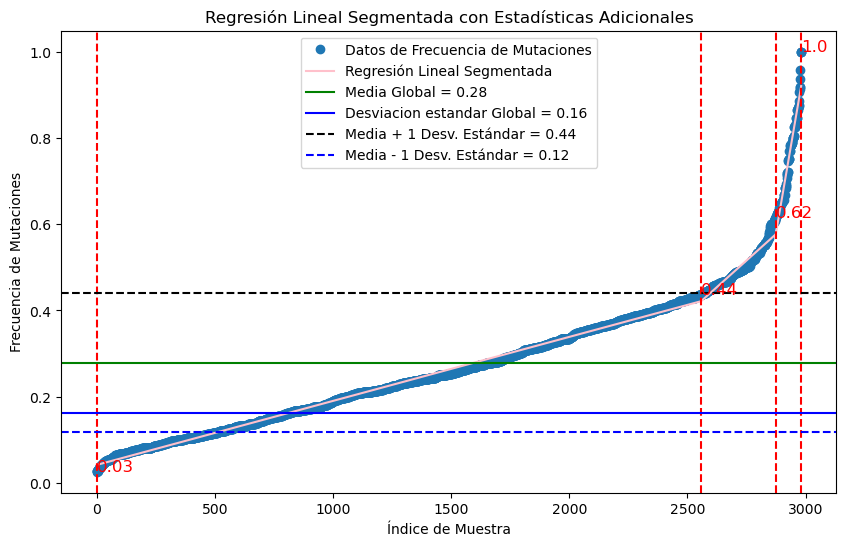

Segmento 1: Media = 0.23146040269591722, Desviación Estándar = 0.1096747940812159
Segmento 2: Media = 0.4983218367706882, Desviación Estándar = 0.04638200924163128
Segmento 3: Media = 0.7409885602741971, Desviación Estándar = 0.09442767929960769


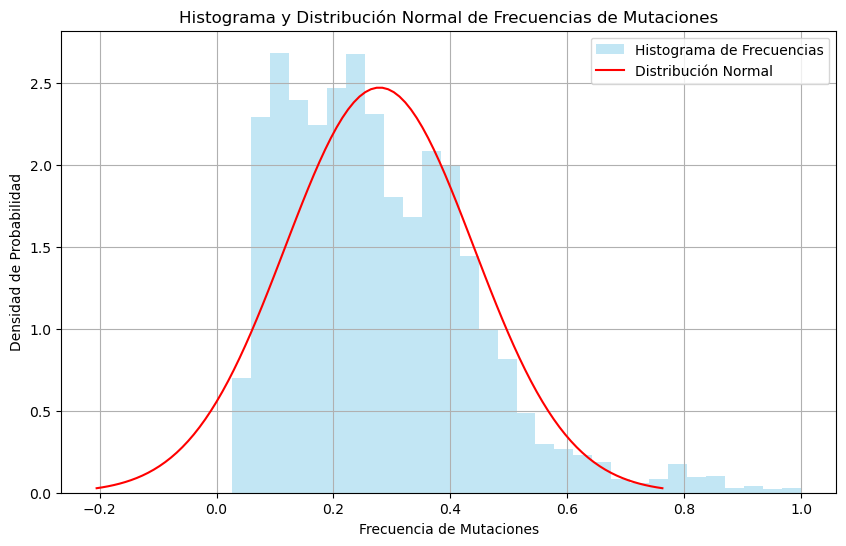

In [24]:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import pwlf


    # Asegurarse de que los datos están ordenados y eliminar NaNs e Infs
    df_drop = df_drop.sort_values(by='mutant_allele_frequency').reset_index(drop=True)
    df_drop = df_drop.replace([np.inf, -np.inf], np.nan).dropna(subset=['mutant_allele_frequency'])
    
    # Extraer la columna de frecuencias de mutaciones
    mutation_frequencies = df_drop['mutant_allele_frequency'].values
    
    # Definir el número de segmentos
    num_segments = 3  # Ajusta según sea necesario
    
    # Crear el modelo de regresión lineal segmentada
    piecewise_model = pwlf.PiecewiseLinFit(np.arange(len(mutation_frequencies)), mutation_frequencies)
    
    # Ajustar el modelo
    res = piecewise_model.fit(num_segments)
    
    # Obtener los puntos de cambio (breakpoints)
    breakpoints = piecewise_model.fit_breaks
    
    # Redondear los umbrales encontrados
    umbrales = [mutation_frequencies[int(bp)] for bp in breakpoints]
    umbrales_redondeados = [round(mutation_frequencies[int(bp)], 2) for bp in breakpoints]
    
    print(f"Puntos de cambio: {breakpoints}")
    print(f"Umbrales: {umbrales}")
    print(f"Umbrales redondeados: {umbrales_redondeados}")
    
    # Calcular estadísticas globales
    media_global = np.mean(mutation_frequencies)
    std_global = np.std(mutation_frequencies)
    
    # Calcular estadísticas por segmento
    segmentos = np.digitize(mutation_frequencies, bins=umbrales)
    estadisticas_segmentos = {}
    for i in range(1, len(umbrales)):
        segmento = mutation_frequencies[segmentos == i]
        estadisticas_segmentos[f'Segmento {i}'] = {
            'Media': np.mean(segmento),
            'Desviación estándar': np.std(segmento)
        }
    
    # Graficar los resultados
    plt.figure(figsize=(10, 6))
    plt.plot(mutation_frequencies, 'o', label='Datos de Frecuencia de Mutaciones')
    x_vals = np.arange(len(mutation_frequencies))
    y_pred = piecewise_model.predict(x_vals)
    plt.plot(x_vals, y_pred, color='pink', label='Regresión Lineal Segmentada')
    for i, bp in enumerate(breakpoints):
        plt.axvline(x=bp, color='r', linestyle='--')
        plt.text(bp, umbrales[i], f'{umbrales_redondeados[i]}', color='red', fontsize=12)
    
    # Añadir líneas de media y desviación estándar globales con etiquetas
    plt.axhline(y=media_global, color='green', linestyle='-', label=f'Media Global = {media_global:.2f}')
    plt.axhline(y=std_global, color='blue', linestyle='-', label=f'Desviacion estandar Global = {std_global:.2f}')
    plt.axhline(y=media_global + std_global, color='black', linestyle='--', label=f'Media + 1 Desv. Estándar = {media_global + 1 * std_global:.2f}')
    plt.axhline(y=media_global - std_global, color='blue', linestyle='--', label=f'Media - 1 Desv. Estándar = {media_global - 1 * std_global:.2f}')
    
    plt.xlabel('Índice de Muestra')
    plt.ylabel('Frecuencia de Mutaciones')
    plt.title('Regresión Lineal Segmentada con Estadísticas Adicionales')
    plt.legend()
    plt.show()
    
    # Mostrar estadísticas de segmentos
    for segmento, stats in estadisticas_segmentos.items():
        print(f"{segmento}: Media = {stats['Media']}, Desviación Estándar = {stats['Desviación estándar']}")
            
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.stats import norm
    
    plt.figure(figsize=(10, 6))
    
    # Histograma de frecuencias de mutaciones
    plt.hist(mutation_frequencies, bins=30, density=True, alpha=0.5, color='skyblue', label='Histograma de Frecuencias')
    
    # Curva de densidad de probabilidad de la distribución normal
    mu, sigma = np.mean(mutation_frequencies), np.std(mutation_frequencies)
    x_normal = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
    pdf_normal = norm.pdf(x_normal, mu, sigma)
    plt.plot(x_normal, pdf_normal, 'r-', label='Distribución Normal')

    plt.xlabel('Frecuencia de Mutaciones')
    plt.ylabel('Densidad de Probabilidad')
    plt.title('Histograma y Distribución Normal de Frecuencias de Mutaciones')
    plt.legend()
    plt.grid(True)
    plt.show()

    
    
    
        


In [25]:
df_drop.shape

(2982, 12)

In [27]:
#interpro_code = 'IPR000333'
family_name = 'STKR'
ruta = '../data/mutaciones/df_frecuencias_mut_{0}.csv'.format(family_name)
df_drop.to_csv(ruta, index=False)

In [28]:
df_drop.columns

Index(['Gen_names', 'aa_mutation', 'cds_mutation', 'mutated_from_allele',
       'mutated_to_allele', 'consequence_type', 'project_code', 'tipo_cancer',
       'total_read_count', 'mutant_allele_read_count',
       'mutant_allele_frequency', 'clasificacion'],
      dtype='object')

In [29]:
df_drop.shape

(2982, 12)

In [30]:
df_drop['aa_mutation'].nunique()

2606